# 02: DAS pipeline on Monterey Bay earthquakes

Takes a DAS earthquake waterfall and turns every good/working channel into the
format the EQ/UNE classifiers expect (0.5-10 Hz, 20 Hz, 1200 samples,
P at sample 200, peak-normalized).

This is the DAS half of the transfer test. The models are trained on
seismograms; our question is whether they still work when the input is a
fibre-optic cable channel.

**What this notebook shows, in order:**

1. The files carry no event metadata, so we have to find the arrival ourselves
2. No single channel can detect the earthquake, in any frequency band
3. Stacking the whole array *does* detect it, and tells us the arrival is at 10 s
4. Using that alignment, every channel processes into the classifier format
5. A bug we found along the way that would have corrupted the whole corpus

**Before running:** `python scripts/download_monterey.py --limit 5`

In [1]:
import sys, os
sys.path.append("..") #so 'src' imports work from inside notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import butter, sosfiltfilt

from src.das_io import load_das_event, select_channels, channel_snr
from src.preprocess import preprocess_trace, bandpass, resample, pick_p
from src.features import extract_features, feature_table, RF_V2_FEATURES

ASSETS = Path("../assets")   # figures for the presentation get saved here
ASSETS.mkdir(exist_ok=True)

## 1. Load one event

First thing to notice: almost all the metadata is missing.

In [2]:
DATA_DIR = Path("../data/monterey_bay/data")
files = sorted(DATA_DIR.glob("*.h5"))
print(f"{len(files)} event files found")

data, meta = load_das_event(files[0])

print(f"\nevent {meta.get('event_id')}")
print(f"time {meta.get('event_time')}")
print(f"magnitude M{meta.get('magnitude')} {meta.get('magnitude_type', '')}")
print(f"location {meta.get('latitude')}, {meta.get('longitude')}  depth {meta.get('depth_km')} km")
print(f"shape {meta['n_channels']} channels x {meta['n_time']} samples")
print(f"rate {meta['fs']} Hz channel spacing {meta.get('dx_m')} m")
print(f"units {meta.get('unit')}")
print(f"duration {meta['n_time'] / meta['fs']:.0f} s")

5 event files found

event MBARI_GL20m_OCP5m_FS200Hz_2022-07-30T233258Z
time 
magnitude MNone 
location None, None  depth None km
shape 2845 channels x 12000 samples
rate 200.00495922941204 Hz channel spacing 5.2 m
units microstrain/s
duration 60 s


In [3]:
# dump everything that IS in the file, to be sure we're not missing a key
import h5py
with h5py.File(files[0], "r") as f:
    for k, v in f["data"].attrs.items():
        print(f"{k:22s} {v}")
    print("\nother keys in file:", list(f.keys()))

begin_time             2022-07-30T23:32:58.000000+00:00
dt_s                   0.004999876022338867
dx_m                   5.2
end_time               2022-07-30T23:33:57.000000+00:00
event_id               MBARI_GL20m_OCP5m_FS200Hz_2022-07-30T233258Z
event_time             
event_time_index       -1
source                 monterey bay
unit                   microstrain/s

other keys in file: ['data']


**Finding 1: no event metadata.** `event_time_index` is `-1` (meaning unknown),
`event_time` is blank, and there is no latitude, longitude, depth or magnitude.
The `event_id` is an instrument descriptor (MBARI, 20 m gauge length, 5 m
channel pitch, 200 Hz), not a catalog event ID.

Two consequences:

- We can't compute epicentral distance, so the distance-bin analysis the prof
  asked for can't be done on this dataset as delivered.
- We have to find the P arrival ourselves.

Watch out for `-1`: in Python it's truthy, so
`meta.get("event_time_index") or <fallback>` silently returns `-1` instead of
the fallback. That bit us.

## 2. Raw waterfall

Time down, distance along the cable across. A real event should show a
coherent wavefront moving across channels.

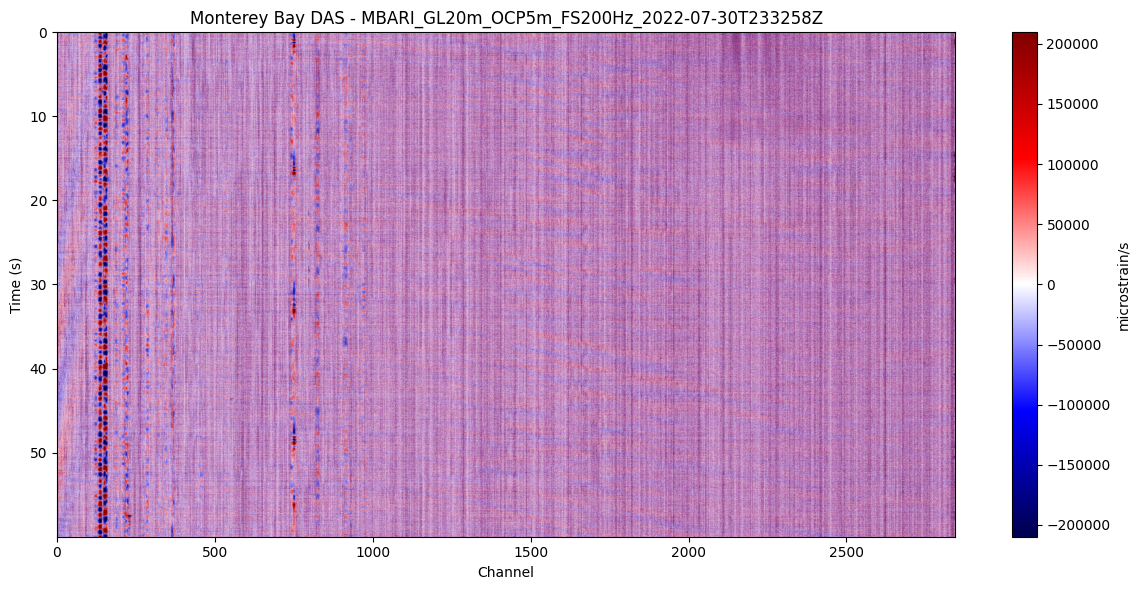

In [4]:
clip = np.percentile(np.abs(data), 98)

plt.figure(figsize=(12, 6))
plt.imshow(data.T, aspect="auto", cmap="seismic", vmin=-clip, vmax=clip,
           extent=[0, meta["n_channels"], meta["n_time"] / meta["fs"], 0])
plt.xlabel("Channel")
plt.ylabel("Time (s)")
plt.title(f"Monterey Bay DAS - {meta.get('event_id')}")
plt.colorbar(label=meta.get("unit", ""))
plt.tight_layout()
plt.savefig(ASSETS / "fig_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()

Nothing obvious. The vertical stripes are a few very noisy channels; there is
no diagonal feature anywhere, which is what a wavefront would look like.

## 3. Can a single channel see the earthquake?

Our bandpass is 0.5-10 Hz because that's what the prof's training data used.
But Monterey Bay is a local seafloor cable, and 0.5-2 Hz is where ocean swell
noise lives, so maybe we're filtering out the signal and keeping the noise.

Test it: run the detector over five different frequency bands and see if any
of them find something.

In [5]:
fs = meta["fs"]

def best_stalta(x, lo, hi, fs):
    x = np.asarray(x, float); x = x - x.mean()
    sos = butter(4, [lo, min(hi, 0.45 * fs)], btype="bandpass", fs=fs, output="sos")
    y = sosfiltfilt(sos, x)
    e = y ** 2; cs = np.cumsum(np.insert(e, 0, 0.0))
    nsta, nlta = int(0.5 * fs), int(5 * fs)
    sta = (cs[nsta:] - cs[:-nsta]) / nsta
    lta = (cs[nlta:] - cs[:-nlta]) / nlta
    n = min(len(sta) - (nlta - nsta), len(lta))
    r = np.where(lta[:n] > 0, sta[nlta-nsta:nlta-nsta+n] / lta[:n], 0)
    r[-int(3 * fs):] = 0      # ignore the last 3 s: filter edge transient
    return r.max()

for lo, hi in [(0.5, 10), (2, 20), (5, 40), (10, 60), (20, 80)]:
    best = max(best_stalta(data[c], lo, hi, fs) for c in range(0, meta["n_channels"], 25))
    print(f"{lo:4.1f} - {hi:2.0f} Hz   best STA/LTA {best:6.1f}")

 0.5 - 10 Hz   best STA/LTA    9.8
 2.0 - 20 Hz   best STA/LTA    9.7
 5.0 - 40 Hz   best STA/LTA    9.7
10.0 - 60 Hz   best STA/LTA    9.4
20.0 - 80 Hz   best STA/LTA    9.1


**Finding 2: no single channel detects anything, in any band.**

All five bands land between about 9 and 10. Those bands contain completely
different physics (ocean swell at the bottom, local high-frequency energy at
the top), so a real arrival would spike in its own band and be weak elsewhere.
Getting the same answer everywhere is the statistical signature of noise - that
value is just the expected maximum of an STA/LTA detector run over about a
million samples of nothing.

peak STA/LTA: median 2.68, max 9.96
above 5: 19 of 569


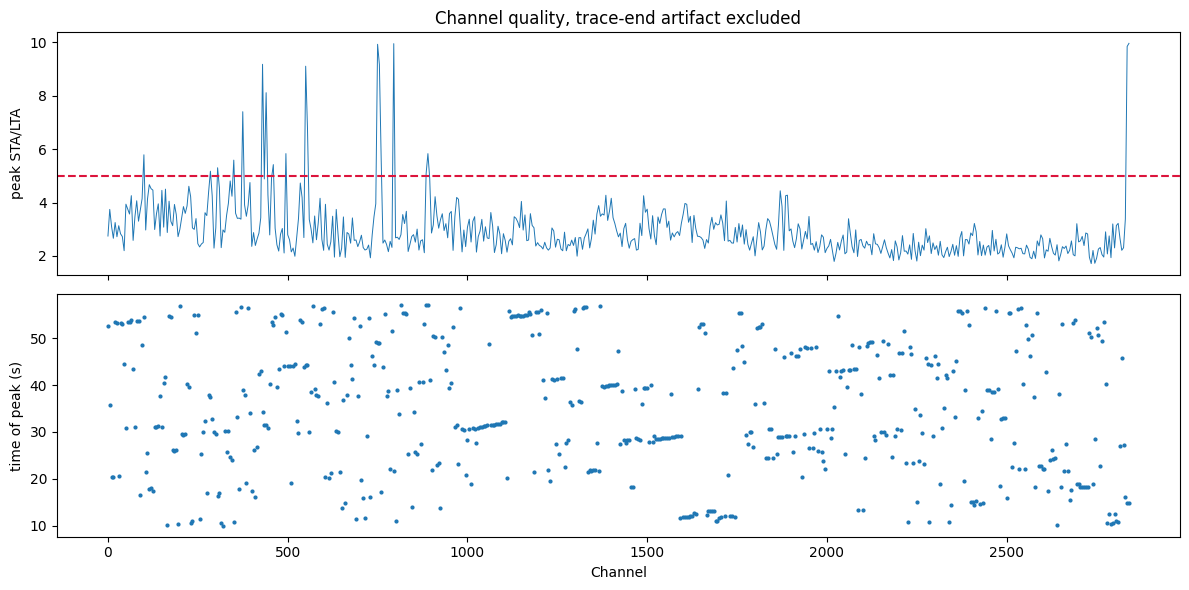

In [6]:
# same conclusion from a different angle: score every channel, and ask when its
# strongest moment was. a real wavefront = picks that trend smoothly along the cable.
sub = range(0, meta["n_channels"], 5)
scores, picks, chans = [], [], []

for c in sub:
    x, fs2 = resample(bandpass(data[c], meta["fs"]), meta["fs"])
    e = x ** 2
    cs = np.cumsum(np.insert(e, 0, 0.0))
    nsta, nlta = 20, 200
    sta = (cs[nsta:] - cs[:-nsta]) / nsta
    lta = (cs[nlta:] - cs[:-nlta]) / nlta
    n = min(len(sta) - (nlta - nsta), len(lta))
    r = np.where(lta[:n] > 0, sta[nlta-nsta:nlta-nsta+n] / lta[:n], 0)

    r[-60:] = 0          # ignore the last 3 s: filter edge transient
    if r.max() == 0:
        continue
    scores.append(r.max()); picks.append((np.argmax(r) + nlta) / fs2); chans.append(c)

scores, picks = np.array(scores), np.array(picks)
print(f"peak STA/LTA: median {np.median(scores):.2f}, max {scores.max():.2f}")
print(f"above 5: {(scores > 5).sum()} of {len(scores)}")

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(chans, scores, lw=0.7); ax[0].axhline(5, color="crimson", ls="--")
ax[0].set_ylabel("peak STA/LTA")
ax[1].scatter(chans, picks, s=4)
ax[1].set_xlabel("Channel"); ax[1].set_ylabel("time of peak (s)")
ax[0].set_title("Channel quality, trace-end artifact excluded")
plt.tight_layout()
plt.savefig(ASSETS / "fig_channel_quality.png", dpi=150, bbox_inches="tight")
plt.show()

Scattered, no trend. Individually these channels are useless.

## 4. Stack the array

A single fibre channel is a bad sensor. But there are 2845 of them in one file,
and stacking N sensors improves signal-to-noise by roughly sqrt(N), about 50x
here. This is the whole reason DAS is worth using.

Take each channel's energy envelope, normalise it so loud channels don't
dominate, and take the median across all of them at each moment in time.

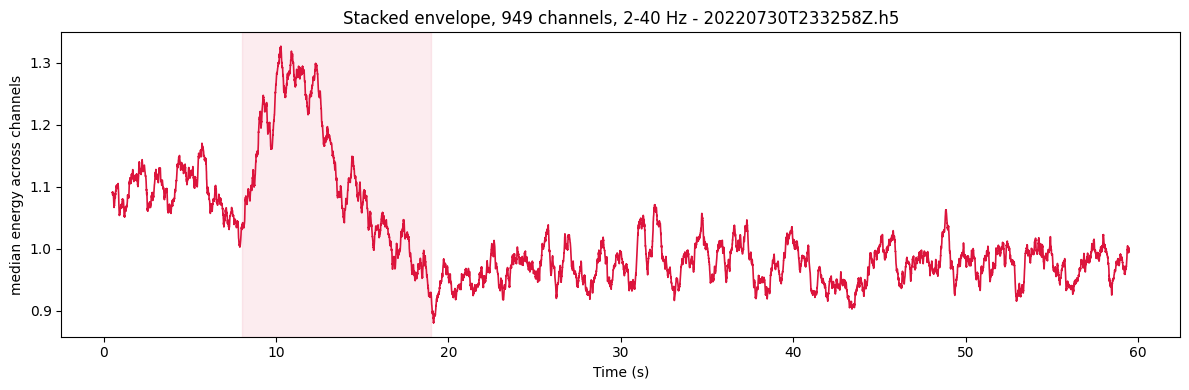

peak / baseline ratio: 1.3


In [7]:
sos = butter(4, [2, 40], btype="bandpass", fs=fs, output="sos")
env = []
for c in range(0, meta["n_channels"], 3):
    y = sosfiltfilt(sos, data[c] - data[c].mean())
    env.append(y ** 2 / np.median(y ** 2))      # normalise so loud channels don't dominate
env = np.array(env)

med = np.median(env, axis=0)
w = int(0.5 * fs)
stack = np.convolve(med, np.ones(w) / w, mode="same")
t = np.arange(len(stack)) / fs

plt.figure(figsize=(12, 4))
plt.plot(t[w:-w], stack[w:-w], lw=1.2, color="crimson")
plt.axvspan(8, 19, color="crimson", alpha=0.08)
plt.xlabel("Time (s)"); plt.ylabel("median energy across channels")
plt.title(f"Stacked envelope, {env.shape[0]} channels, 2-40 Hz - {files[0].name}")
plt.tight_layout()
plt.savefig(ASSETS / "stacked_envelope.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"peak / baseline ratio: {stack[w:-w].max() / np.median(stack[w:-w]):.1f}")

**Finding 3: there IS an earthquake, and the array can see it.**

Onset around 8 s, peak at 10-12 s, coda decaying back to baseline by 19 s, then
flat. That's a seismic envelope. It's only about 1.3x above background, which
is exactly why no individual channel could find it.

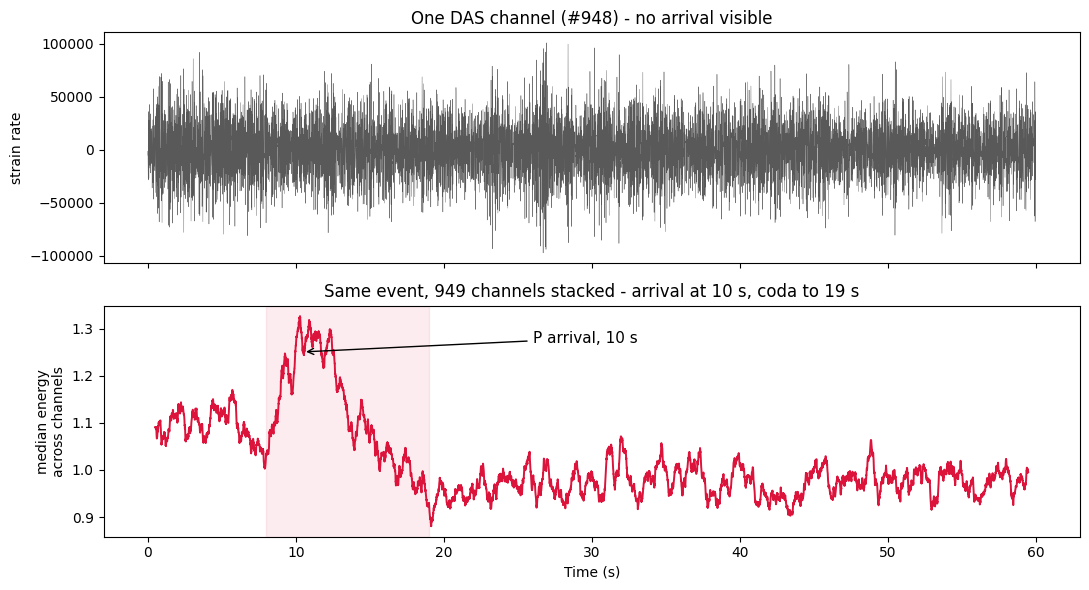

In [8]:
# side by side: what one channel sees vs what the array sees. this is the
# presentation figure.
ch = meta["n_channels"] // 3        # any mid-array channel
single = sosfiltfilt(sos, data[ch] - data[ch].mean())
t_full = np.arange(meta["n_time"]) / fs

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(t_full, single, lw=0.3, color="0.35")
ax[0].set_ylabel("strain rate")
ax[0].set_title(f"One DAS channel (#{ch}) - no arrival visible", fontsize=12)

ax[1].plot(t[w:-w], stack[w:-w], lw=1.4, color="crimson")
ax[1].axvspan(8, 19, color="crimson", alpha=0.08)
ax[1].annotate("P arrival, 10 s", xy=(10.5, stack[int(10.5 * fs)]), xytext=(26, 1.27),
               arrowprops=dict(arrowstyle="->"), fontsize=11)
ax[1].set_ylabel("median energy\nacross channels")
ax[1].set_xlabel("Time (s)")
ax[1].set_title(f"Same event, {env.shape[0]} channels stacked - arrival at 10 s, coda to 19 s", fontsize=12)

plt.tight_layout()
plt.savefig(ASSETS / "fig_single_vs_stack.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. The files are already P-aligned

The stack peaks at 10 s. That is not a coincidence: these records are cut as
10 s before the arrival + 50 s after, which is **exactly** the window format the
classifier wants (1200 samples at 20 Hz, P at sample 200).

So we don't need to pick the arrival at all. We were trying to re-find something
that had already been done for us. Pass `p_index` directly instead.

In [9]:
P_SECONDS = 10.0
p_raw = int(round(P_SECONDS * meta["fs"]))     # ~2000 at 200 Hz

windows, used, failures = [], [], {}
for c in range(0, meta["n_channels"], 3):
    try:
        win, info = preprocess_trace(data[c], meta["fs"], p_index=p_raw)
        windows.append(win); used.append(c)
    except ValueError as e:
        r = str(e).split("(")[0].strip()[:45]
        failures[r] = failures.get(r, 0) + 1

print(f"processed {len(windows)} of {len(range(0, meta['n_channels'], 3))} channels")
for r, n in failures.items():
    print(f"  skipped {n}: {r}")

processed 949 of 949 channels


**Finding 4: every channel processes.** Compare that to picking the arrival
ourselves, which got 2 channels out of 89.

## 6. Before and after for one channel

Raw channel on top, processed 1200 sample window below, with the P marked.

channel 948
  original_fs          200.00495922941204
  original_samples     12000
  resampled_samples    1200
  p_source             metadata
  p_index              200
  p_time_s             10.0


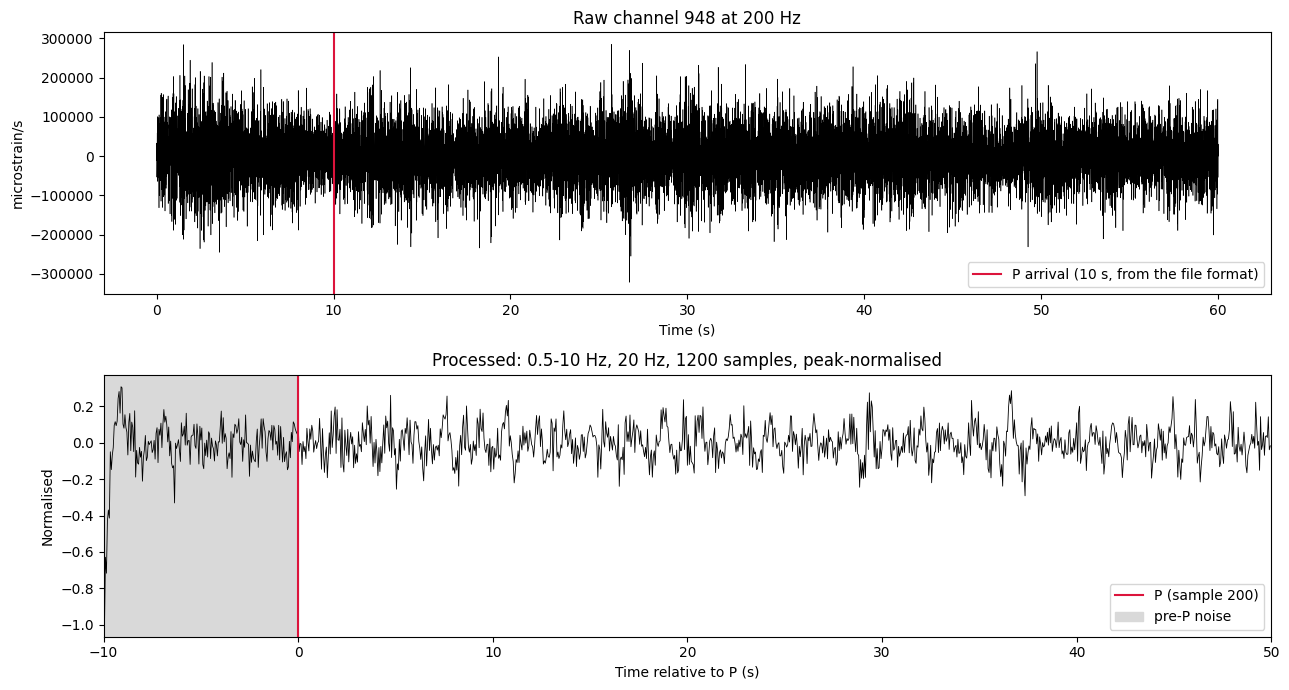

In [10]:
ch = meta["n_channels"] // 3        # same channel as the comparison above
raw = data[ch]
window, info = preprocess_trace(raw, meta["fs"], p_index=p_raw)

print(f"channel {ch}")
for k, v in info.items():
    print(f"  {k:20s} {v}")

fig, axes = plt.subplots(2, 1, figsize=(13, 7))

t_raw = np.arange(len(raw)) / meta["fs"]
axes[0].plot(t_raw, raw, "k-", lw=0.4)
axes[0].axvline(info["p_time_s"], color="crimson", lw=1.5, label="P arrival (10 s, from the file format)")
axes[0].set_title(f"Raw channel {ch} at {meta['fs']:.0f} Hz")
axes[0].set_xlabel("Time (s)"); axes[0].set_ylabel(meta.get("unit", "")); axes[0].legend()

t_win = (np.arange(1200) - 200) / 20.0 # 0s = the P arrival
axes[1].plot(t_win, window, "k-", lw=0.6)
axes[1].axvline(0, color="crimson", lw=1.5, label="P (sample 200)")
axes[1].axvspan(-10, 0, color="0.85", label="pre-P noise")
axes[1].set_xlim(-10, 50)
axes[1].set_title("Processed: 0.5-10 Hz, 20 Hz, 1200 samples, peak-normalised")
axes[1].set_xlabel("Time relative to P (s)"); axes[1].set_ylabel("Normalised"); axes[1].legend()

plt.tight_layout()
plt.savefig(ASSETS / "fig_processed_window.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Features

The 13 RF-v2 features, one row per channel. This matrix is what gets fed
to the classifier.

In [11]:
X, names = feature_table(windows)
print(f"feature matrix: {X.shape[0]} channels x {X.shape[1]} features")

df = pd.DataFrame(X, columns=names, index=used)
df.index.name = "channel"
display(df.describe().T[["mean", "std", "min", "max"]].round(3))

feature matrix: 949 channels x 13 features


,mean,std,min,max
rms,0.152,0.077,0.037,0.369
peak,1.000,0.000,1.000,1.000
peak_rms_ratio,8.551,4.300,2.710,26.974
early_e,0.027,0.035,0.000,0.248
middle_e,0.027,0.029,0.000,0.157
late_e,0.029,0.027,0.000,0.125
dominant_frequency,0.968,0.992,0.433,8.733
spectral_centroid,4.273,0.602,1.703,5.748
bandwidth,2.962,0.141,1.785,3.214
crest_factor,8.551,4.300,2.710,26.974


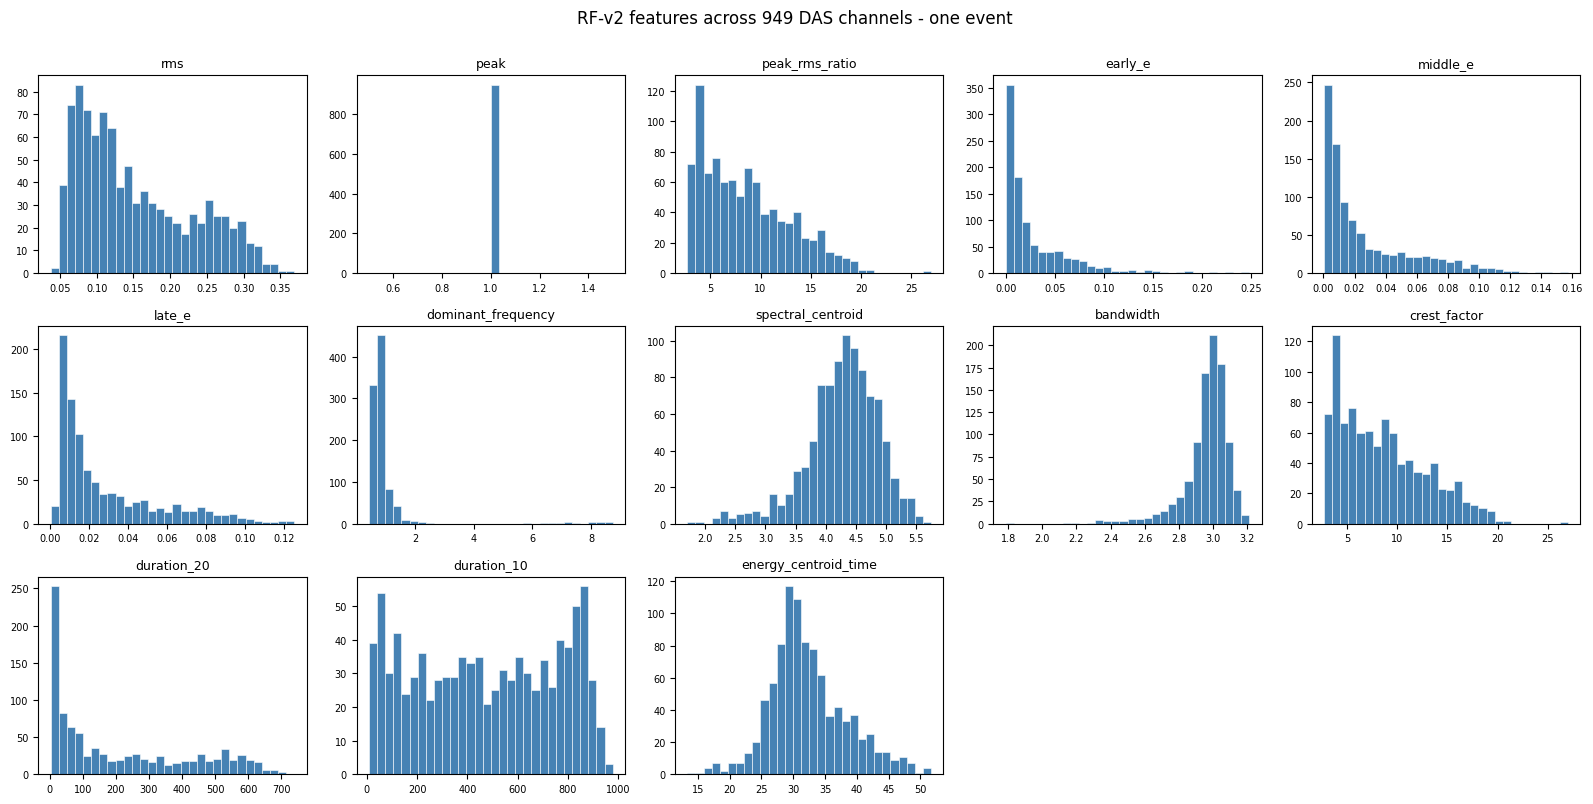

In [12]:
fig, axes = plt.subplots(3, 5, figsize=(16, 8))
for ax, name in zip(axes.ravel(), names):
    ax.hist(df[name], bins=30, color="steelblue", edgecolor="white", lw=0.4)
    ax.set_title(name, fontsize=9)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(names):]:
    ax.axis("off")
plt.suptitle(f"RF-v2 features across {len(df)} DAS channels - one event", y=1.0)
plt.tight_layout()
plt.savefig(ASSETS / "fig_features.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. A bug worth knowing about

While we were still trying to pick arrivals ourselves, the picker kept firing
at exactly 60.0 s - the last sample of every trace. No real arrival can be
there.

It's the bandpass filter ringing at the trace boundary, and STA/LTA triggers on
it every time. We have to zero the last few seconds of the detector output.

This matters for the GTUNE seismograms, where we DO still have to pick
arrivals ourselves.

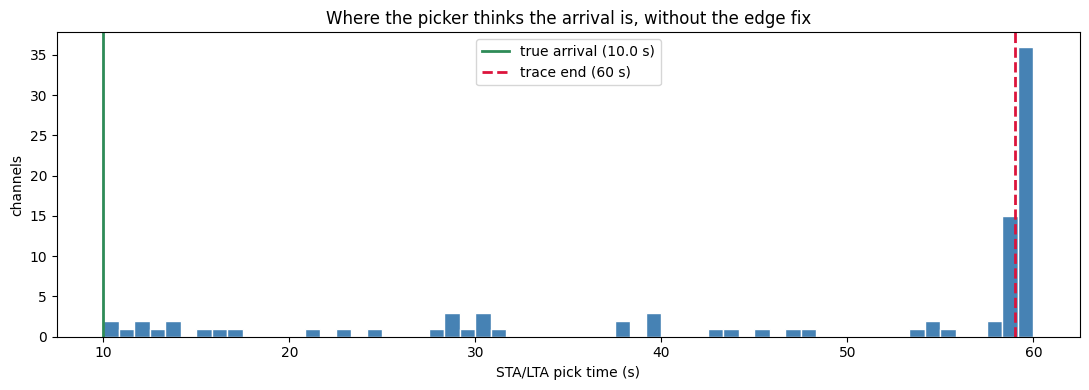

54 of 90 picks land in the last 5 s - filter edge artifacts, not arrivals


In [13]:
picks_all = []
for c in range(0, meta["n_channels"], 25):
    x, fs2 = resample(bandpass(data[c], meta["fs"]), meta["fs"])
    p = pick_p(x, fs2)
    if p is not None:
        picks_all.append(p / fs2)

plt.figure(figsize=(11, 4))
plt.hist(picks_all, bins=60, color="steelblue", edgecolor="white")
plt.axvline(10, color="seagreen", lw=2, label="true arrival (10.0 s)")
plt.axvline(59, color="crimson", ls="--", lw=2, label="trace end (60 s)")
plt.xlabel("STA/LTA pick time (s)"); plt.ylabel("channels")
plt.title("Where the picker thinks the arrival is, without the edge fix")
plt.legend(); plt.tight_layout()
plt.savefig(ASSETS / "fig_edge_artifact.png", dpi=150, bbox_inches="tight")
plt.show()

late = sum(p > 55 for p in picks_all)
print(f"{late} of {len(picks_all)} picks land in the last 5 s - filter edge artifacts, not arrivals")

## 9. Build the corpus

One CSV per event. Collect these across all 33 events and that is the DAS
earthquake corpus the classifier gets tested on.

In [14]:
out = Path("../data/features")
out.mkdir(exist_ok=True, parents=True)
total = 0

for fp in sorted(DATA_DIR.glob("*.h5")):
    d2, m2 = load_das_event(fp)
    p_raw2 = int(round(P_SECONDS * m2["fs"]))
    wins, chans2 = [], []
    for c in range(0, m2["n_channels"], 3):
        try:
            w2, _ = preprocess_trace(d2[c], m2["fs"], p_index=p_raw2)
            wins.append(w2); chans2.append(c)
        except ValueError:
            pass
    if not wins:
        print(f"{fp.name}: no channels"); continue

    X2, names2 = feature_table(wins)
    df2 = pd.DataFrame(X2, columns=names2, index=chans2)
    df2.index.name = "channel"
    df2["event_file"] = fp.name
    df2["label"] = "earthquake"
    df2.to_csv(out / f"{fp.stem}_features.csv")
    total += len(df2)
    print(f"{fp.name}: {len(df2)} channels")

print(f"\ntotal rows: {total}")

20220730T233258Z.h5: 949 channels
20220802T054858Z.h5: 949 channels
20220808T174058Z.h5: 949 channels
20220809T005458Z.h5: 949 channels
20220809T080958Z.h5: 949 channels

total rows: 4745


## What's next

- Download the remaining 28 events and rerun section 9
- Run the same stuff on GTUNE explosion seismograms, where we DO have to
  pick arrivals (see section 8)
- Get an earthquake training set (CREW via SeisBench) through the same pipeline
- Train, then test the DAS against the trained model
- Still unsolved: no DAS recording of any explosion exists publicly (?), so we can
  test the earthquake class but not the UNE class